# 00 · Acquisition 101 — your first ultrasound echoes

Welcome! In this notebook you will use the **minus** board to send a sound pulse into the water (or a gel pad, or your
arm), listen to what comes back, and turn it into a picture. You do not need to know anything about electronics or signal
processing: run each cell with **Shift + Enter**, read the text, look at the plot. The cells marked **✋ Try it** are for you
to change.

**What is going on, in one paragraph.** The *transducer* (the probe) is a small piezoelectric disc. When the board hits it
with a short voltage spike, it rings like a bell, but at 3–4 million vibrations per second (3–4 **MHz**), far too high to
hear. That sound travels into the material, and every time it meets a change (a wall, a bone, the bottom of a glass) a bit
of it bounces back: an **echo**. The same disc turns the returning sound back into a tiny voltage, which the board amplifies
and measures 25 million times per second. The time an echo takes to come back tells you **how far away** the reflector is.

> minus is a teaching and research tool, **not a medical device**: nothing it shows is a diagnosis.

**What you need:** the board plugged into USB, the probe connected and touching water / gel / the object to look at.

## 1. Connect to the board

This cell loads the tools and opens the connection. If it complains that no board is found, check the USB cable and ask a
helper.

In [1]:
import sys, time
sys.path.insert(0, "../library")            # where the minus library lives in this repository
import numpy as np
import matplotlib.pyplot as plt
from minus import Minus
from minus.live import hilbert_envelope

dev = Minus()                               # finds the board on USB
print(dev.version())                        # which firmware the board runs
dev.rgb(0, 255, 0)                          # the board's LED turns green: we are talking to it

Version(name='minus-rp2354', version='1.1.9', proto=15, built='Nov 22 2026 15:47:10', pico_sdk='2.1.0', board='minus v1.1', flash_kb=2048, chip='RP2354A', chip_id=805325095, package_sel=1, chip_rev='A3', unique_id='7D4466C63B374C98')


/home/kelu/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


True

## 2. Your first echo

`dev.pe()` stands for **pulse-echo**: the board fires one pulse and records the next 164 microseconds (µs) of signal.
The result is a list of 4095 numbers, one every 40 nanoseconds. We plot them against time.

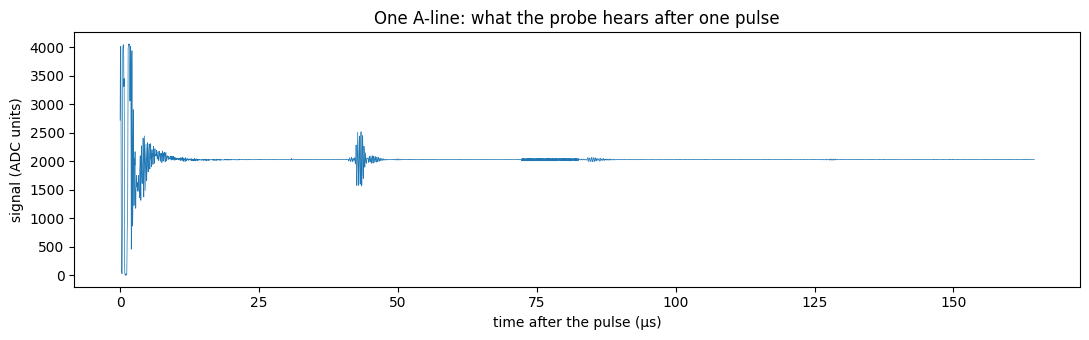

4095 measurements, one every 40 ns, 165 µs in total


In [2]:
dev.gain(0, 1, 0)                           # a moderate amplification (more on this in section 5)
shot = dev.pe()

plt.figure(figsize=(11, 3.5))
plt.plot(shot.t_us, shot.samples, lw=0.5)
plt.xlabel("time after the pulse (µs)"); plt.ylabel("signal (ADC units)")
plt.title("One A-line: what the probe hears after one pulse")
plt.tight_layout(); plt.show()
print(f"{shot.n} measurements, one every {shot.dt_ns:.0f} ns, {shot.t_us[-1]:.0f} µs in total")

**How to read this plot** (it is called an **A-line**, A for *amplitude*):

* The big burst at the very start is the **main bang**: the pulse itself, plus the probe still ringing. Nothing can be seen
  in the first ~20 µs.
* The flat-ish part is **noise**: the small random wiggles every electronic measurement has.
* Each burst further right is an **echo**. The later it arrives, the further away the reflector.
* The signal swings around a middle value (~2048). The board measures with 12 bits: values go from 0 to 4095.

## 3. Zoom on one echo

Sound is a wave: zoom in and you can see each vibration of the echo. Let's find the strongest echo after the main bang
automatically and zoom on it.

strongest echo at 43.5 µs


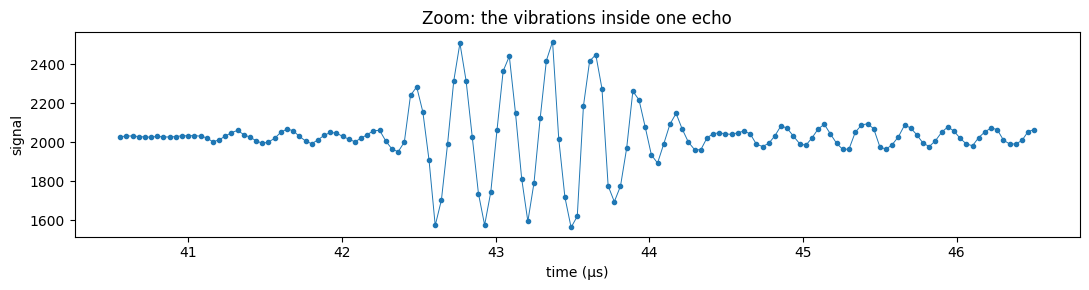

about 3.6 vibrations per µs = 3.6 MHz (the probe's frequency)


In [3]:
y = shot.samples.astype(float)
env = hilbert_envelope(y)                    # the "outline" of the signal (explained in section 6)
after_bang = (shot.t_us > 20) & (shot.t_us < shot.t_us[-1] - 5)   # skip the main bang and the last few µs (edge effect)
i_echo = np.argmax(np.where(after_bang, env, 0))
t_echo = shot.t_us[i_echo]
print(f"strongest echo at {t_echo:.1f} µs")

zoom = (shot.t_us > t_echo - 3) & (shot.t_us < t_echo + 3)
plt.figure(figsize=(11, 3))
plt.plot(shot.t_us[zoom], y[zoom], ".-", lw=0.7)
plt.xlabel("time (µs)"); plt.ylabel("signal"); plt.title("Zoom: the vibrations inside one echo")
plt.tight_layout(); plt.show()

# how many vibrations per microsecond? count the zero crossings around the echo
yz = y[zoom] - y[zoom].mean()
crossings = np.sum(np.diff(np.sign(yz)) != 0)
print(f"about {crossings / 2 / 6:.1f} vibrations per µs = {crossings / 2 / 6:.1f} MHz (the probe's frequency)")

## 4. From time to distance

Sound travels at about **1480 m/s in water** and **1540 m/s in soft tissue** (≈ 1.5 mm per µs). The echo has to go *there
and back*, so:

$$\text{distance} = \frac{\text{speed of sound} \times \text{time}}{2}$$

The board does not know the speed of sound; we tell it. `shot.depth_mm(c)` turns the time axis into a distance axis.

the strongest echo is 32.2 mm away (for 1480 m/s)


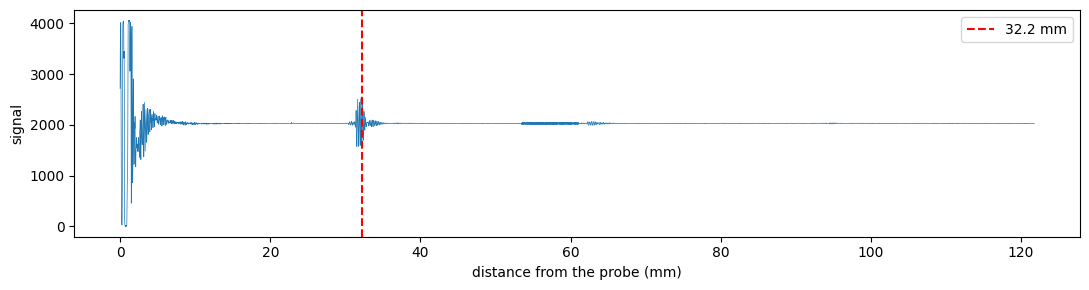

In [4]:
speed = 1480                                 # m/s: water. ✋ Try 1540 (tissue) or 6300 (aluminium)
depth = shot.depth_mm(speed)
print(f"the strongest echo is {depth[i_echo]:.1f} mm away (for {speed} m/s)")

plt.figure(figsize=(11, 3))
plt.plot(depth, y, lw=0.5)
plt.axvline(depth[i_echo], color="r", ls="--", label=f"{depth[i_echo]:.1f} mm")
plt.xlabel("distance from the probe (mm)"); plt.ylabel("signal"); plt.legend()
plt.tight_layout(); plt.show()

✋ **Try it:** take a ruler and measure the distance between the probe and the reflector (for example the bottom of the
container). Does it match? Move the probe closer, re-run the cell in section 2 and then this one: the echo moves left.

You may see a second echo at about **twice** the distance: the sound bounced on the reflector, came back to the probe, bounced
again and made the trip a second time. These are **reverberations**.

## 5. Gain: turning the volume up

Echoes from far away or weak reflectors are small. The board has an amplifier with a few fixed settings (**gain**). Too
little gain and the echoes drown in the noise; too much and the signal hits the limits (0 or 4095) and gets clipped:
**saturation**.

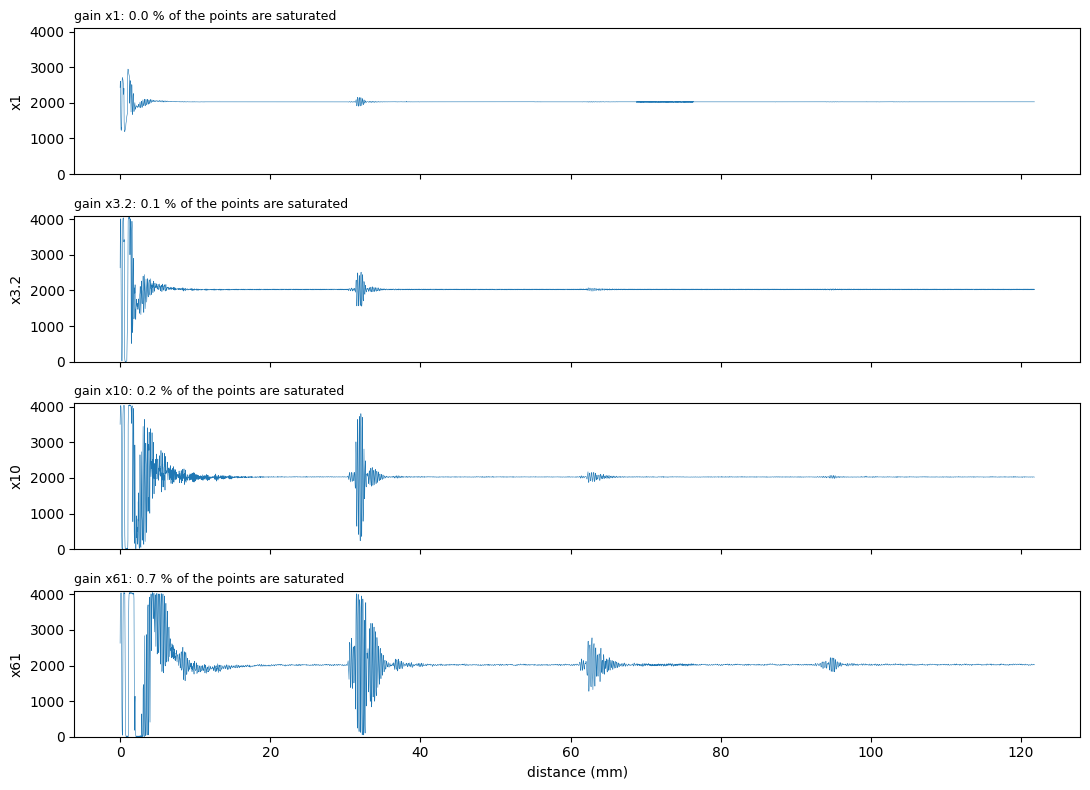

Gain(leg=0, rf_ohm=2200.0, oa1=1.0, oa1_unity=True, oa2=3.2, oa2_unity=False, total=3.2, total_db=10.1)

In [5]:
settings = {"x1": (0, 1, 1), "x3.2": (0, 1, 0), "x10": (0, 0, 0), "x61": (2, 0, 0)}
fig, ax = plt.subplots(len(settings), 1, figsize=(11, 8), sharex=True)
for a, (name, g) in zip(ax, settings.items()):
    dev.gain(*g)
    s = dev.pe()
    clipped = np.mean((s.samples < 5) | (s.samples > 4090)) * 100
    a.plot(s.depth_mm(speed), s.samples, lw=0.4)
    a.set_ylim(0, 4095); a.set_ylabel(name)
    a.set_title(f"gain {name}: {clipped:.1f} % of the points are saturated", fontsize=9, loc="left")
ax[-1].set_xlabel("distance (mm)")
plt.tight_layout(); plt.show()
dev.gain(0, 1, 0)

✋ **Try it:** which gain shows the first echo best without flattening it against the top or bottom? Which one shows the
small, far echoes? (There is no single right answer: this is why real scanners raise the gain with depth, called *time-gain
compensation*.)

## 6. The envelope: the outline of the echoes

The raw signal goes up and down millions of times per second; for a picture we only want **how strong** the echo is at each
depth. That is the **envelope**: the smooth curve that hugs the peaks. Echo strengths span a huge range, so we draw it in
**decibels (dB)**: every +20 dB means 10 times stronger.

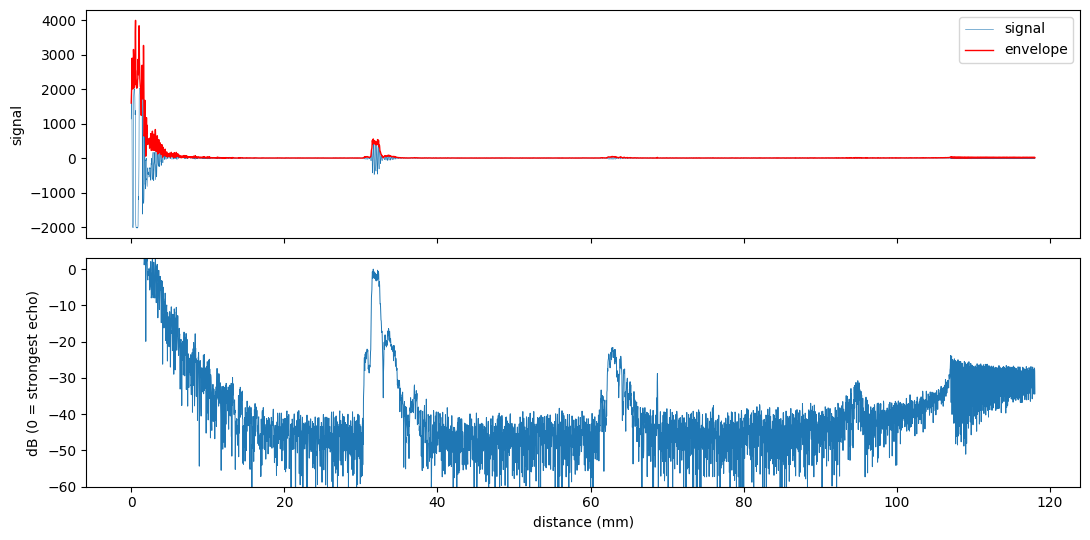

In [6]:
shot = dev.pe(); y = shot.samples.astype(float)
env = hilbert_envelope(y)
keep = shot.t_us < shot.t_us[-1] - 5              # hide the last 5 µs (the envelope calculation misbehaves at the edge)

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
d = shot.depth_mm(speed)
ax[0].plot(d[keep], (y - y.mean())[keep], lw=0.4, label="signal")
ax[0].plot(d[keep], env[keep], "r", lw=1, label="envelope")
ax[0].legend(); ax[0].set_ylabel("signal")
db = 20 * np.log10(np.maximum(env, 0.5) / env[keep & (shot.t_us > 20)].max())
ax[1].plot(d[keep], db[keep], lw=0.7)
ax[1].set_ylim(-60, 3); ax[1].set_ylabel("dB (0 = strongest echo)"); ax[1].set_xlabel("distance (mm)")
plt.tight_layout(); plt.show()

The board can also compute the envelope **by itself** and send only that (8 times fewer numbers): `dev.envbp(...)` keeps
only the frequencies the probe produces (around 3.3 MHz) before taking the outline, which removes most of the noise.

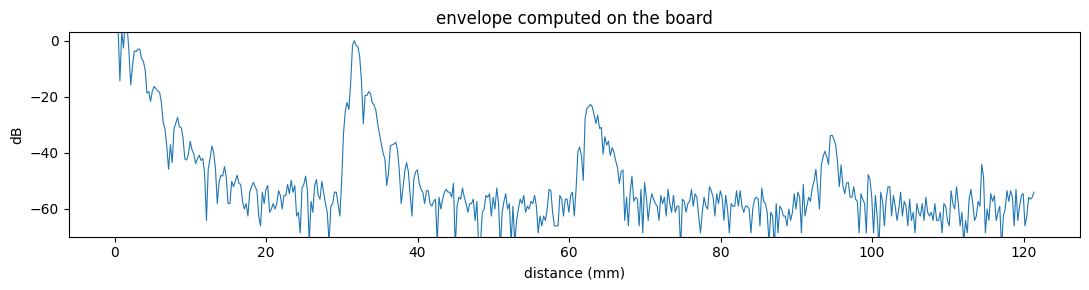

In [7]:
e = dev.envbp(8)                              # one envelope value every 8 measurements
plt.figure(figsize=(11, 3))
plt.plot(e.depth_mm(speed), 20 * np.log10(np.maximum(e.values, 0.1) / e.values[e.t_us > 20].max()), lw=0.8)
plt.ylim(-70, 3); plt.xlabel("distance (mm)"); plt.ylabel("dB"); plt.title("envelope computed on the board")
plt.tight_layout(); plt.show()

## 7. Noise and averaging

Fire several pulses and average them: the echoes are the same every time, the random noise is not, so the noise partly
cancels out. **The order matters**: average the raw signals first, *then* take the envelope. The envelope is always
positive, so averaging envelopes cannot make the noise cancel.

quiet zone: 95–115 µs
 1 shot(s): noise 2.42 (average first)   2.42 (envelope first)   strongest echo   635
16 shot(s): noise 2.65 (average first)   5.38 (envelope first)   strongest echo   485
64 shot(s): noise 1.73 (average first)   5.42 (envelope first)   strongest echo   492


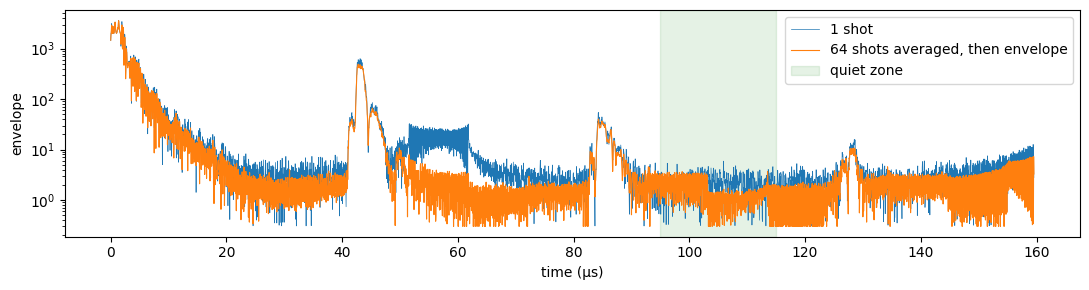

In [8]:
shots = np.array([dev.pe().samples.astype(float) for _ in range(64)])   # 64 pulses, ~2 s
t = shot.t_us
# a quiet zone with no echo: the 20 µs window (after the main bang) where the first shot is weakest
e0 = hilbert_envelope(shots[0]); starts = np.arange(25, t[-1] - 25, 2.0)
q0 = starts[np.argmin([np.median(e0[(t > s) & (t < s + 20)]) for s in starts])]
quiet = (t > q0) & (t < q0 + 20)
rms = lambda e: np.sqrt(np.mean(e[quiet] ** 2))
print(f"quiet zone: {q0:.0f}–{q0 + 20:.0f} µs")
for n in (1, 16, 64):
    good = hilbert_envelope(shots[:n].mean(axis=0))                       # average, then envelope
    bad = np.mean([hilbert_envelope(y) for y in shots[:n]], axis=0)       # envelope, then average
    print(f"{n:2d} shot(s): noise {rms(good):4.2f} (average first)   {rms(bad):4.2f} (envelope first)   "
          f"strongest echo {good[(t > 20) & (t < t[-1] - 5)].max():5.0f}")
k = t < t[-1] - 5
plt.figure(figsize=(11, 3))
plt.semilogy(t[k], np.maximum(hilbert_envelope(shots[0]), .3)[k], lw=0.5, label="1 shot")
plt.semilogy(t[k], np.maximum(hilbert_envelope(shots.mean(axis=0)), .3)[k], lw=0.8, label="64 shots averaged, then envelope")
plt.axvspan(q0, q0 + 20, color="g", alpha=0.1, label="quiet zone")
plt.xlabel("time (µs)"); plt.ylabel("envelope"); plt.legend(); plt.tight_layout(); plt.show()

What to notice:

* Averaging first lowers the noise, but less than the textbook rule (64 shots → 8 times less), and not smoothly with
  only a few shots. Part of the "noise" here is not random: it is interference that is the same on every shot, and
  averaging cannot remove it. Bursts that appear on one shot only (look at the plot) do get averaged away.
* The strongest echo also gets a bit *smaller*. The pulse does not start at exactly the same instant on every shot (up to
  40 ns of jitter), so the vibrations of successive echoes do not line up perfectly and partly cancel. Real scanners line the
  shots up before averaging.
* Envelope first, then average: the noise does not go down at all.

## 8. From lines to an image: M-mode

One A-line is one "look" in one direction. Fire many in a row and stack them side by side: time goes left to right, depth top
to bottom, brightness = echo strength. This is called **M-mode** (M for *motion*): if something moves (your hand, the probe,
a muscle), you see it move.

✋ **Try it:** run the cell, and during the 5 seconds slowly move the probe or the reflector.

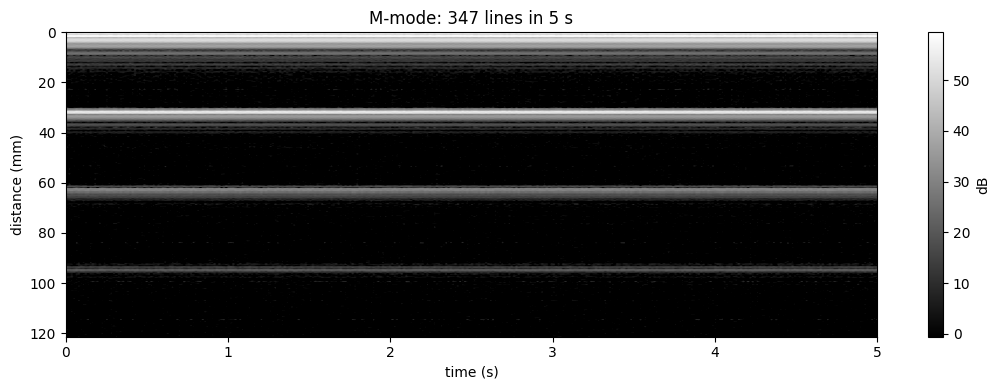

In [9]:
lines, t0 = [], time.time()
while time.time() - t0 < 5:
    lines.append(dev.envbp(8).values)
img = 20 * np.log10(np.maximum(np.array(lines).T, 0.1))
e = dev.envbp(8)
plt.figure(figsize=(11, 4))
top = np.percentile(img, 99.5)
plt.imshow(img, aspect="auto", cmap="gray", vmin=top - 60, vmax=top,
           extent=[0, 5, e.depth_mm(speed)[-1], 0])
plt.xlabel("time (s)"); plt.ylabel("distance (mm)"); plt.title(f"M-mode: {len(lines)} lines in 5 s")
plt.colorbar(label="dB"); plt.tight_layout(); plt.show()

For a **live** view that keeps updating, see notebook `04_live_viewer.ipynb`, or run `python3 -m minus.live` in a terminal.

## 9. ✋ Challenges

1. **Speed of sound:** put the probe at a known distance (ruler) from a flat reflector in water, measure the echo time, and
   compute the speed of sound yourself: $c = 2 \times \text{distance} / \text{time}$. How close to 1480 m/s are you?
2. **Hot and cold:** sound is faster in warmer water. Can you see the echo move when you change the water temperature?
3. **Thickness gauge:** put a plastic plate in the water. You should see two echoes, front and back of the plate. The time
   between them gives its thickness (use about 2700 m/s for acrylic).
4. **Your arm:** with gel, put the probe on your forearm and record an M-mode while you clench your fist.

In [10]:
# ✋ your experiments here


## Words you met

| word | meaning |
|---|---|
| transducer / probe | the piezo disc that turns electricity into sound and back |
| MHz | million vibrations per second |
| pulse-echo | send a short pulse, listen to what comes back |
| A-line | the signal recorded after one pulse (amplitude vs time) |
| main bang | the pulse itself at the start of each A-line |
| gain | amplification of the received signal |
| saturation | the signal is too big and gets cut at 0 or 4095 |
| envelope | the smooth outline of the echoes (how strong, not the vibration) |
| dB | a log scale: +20 dB = 10 × stronger |
| M-mode | many A-lines side by side over time |

Next: `01_getting_started.ipynb` (how the board talks to the computer) and `02_acquisition.ipynb` (all the acquisition
options).

In [11]:
dev.rgb(0, 0, 0)
dev.close()